In [ ]:
import numpy as np
import pandas as pd

In [ ]:
file_path = "/content/cleaned_ASAG2024_train.csv"
df = pd.read_csv(file_path)

df.head()

,question,provided_answer,reference_answer,grade,data_source,normalized_grade,weight,index,answer_word_count,reference_word_count,answer_reference_ratio
0,"Look at the 2 pictures of drops on a flat, wat...",The plain water looks like it does because pla...,Surface tension causes the plain water to look...,0.0,SciEntsBank,0.0,0.000092,4262,24,11,2.181818
1,What is the “Dynamic Host Configuration Protoc...,The Dynamic Host Configuration Protocol (DHCP)...,The Dynamic Host Configuration Protocol (DHCP)...,1.0,SAF,1.0,0.000080,22,81,75,1.080000
2,Why does the level of the water in the straw g...,Because the hotter it is the higher it goes up.,Water expands when water is heated.,0.0,SciEntsBank,0.0,0.000092,2034,10,6,1.666667
3,What requirement has to be met so that you can...,It is a duplex operation so communication has ...,Piggybacking only makes sense if there is a fu...,0.5,SAF,0.5,0.000227,1171,37,27,1.370370
4,Explain in one sentence what each graph tells ...,This graph tells me the number of the tree's r...,"As time increases, the number of tree rings al...",0.0,SciEntsBank,0.0,0.000092,1339,13,10,1.300000


In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nNumerical Summary:")
display(df.describe())

print("\nCategorical Summary:")
display(df.describe(include="object"))

Dataset Shape: (15153, 11)

Column Names:
['question', 'provided_answer', 'reference_answer', 'grade', 'data_source', 'normalized_grade', 'weight', 'index', 'answer_word_count', 'reference_word_count', 'answer_reference_ratio']

Missing Values:
question                  877
provided_answer             0
reference_answer            0
grade                       0
data_source                 0
normalized_grade            0
weight                      0
index                       0
answer_word_count           0
reference_word_count        0
answer_reference_ratio      0
dtype: int64

Duplicate Rows: 0

Data Types:
question                   object
provided_answer            object
reference_answer           object
grade                     float64
data_source                object
normalized_grade          float64
weight                    float64
index                       int64
answer_word_count           int64
reference_word_count        int64
answer_reference_ratio    float64
dtype:

,grade,normalized_grade,weight,index,answer_word_count,reference_word_count,answer_reference_ratio
count,15153.000000,15153.000000,15153.000000,15153.000000,15153.000000,15153.000000,15153.000000
mean,2.003888,0.647158,0.000360,1736.073121,24.426912,32.122748,1.012434
std,3.675595,0.375726,0.001336,1412.654325,40.033461,58.054665,1.802998
min,0.000000,0.000000,0.000056,0.000000,1.000000,1.000000,0.001818
25%,1.000000,0.333333,0.000080,419.000000,7.000000,10.000000,0.495833
50%,2.000000,0.666667,0.000096,1428.000000,12.000000,15.000000,0.777778
75%,3.000000,1.000000,0.000241,2914.000000,21.000000,28.000000,1.181818
max,100.000000,1.000000,0.041667,4968.000000,550.000000,550.000000,160.000000



Categorical Summary:


,question,provided_answer,reference_answer,data_source
count,14276,15153,15153,15153
unique,283,14335,452,7
top,Explain your reasoning.,The problem like that can solve by word sense ...,Terminal 1 and the positive terminal are separ...,SciEntsBank
freq,612,67,188,8611


In [ ]:
# Normalized grade distribution

print("Unique normalized grades:")
print(df["normalized_grade"].nunique())

print("\nSorted unique normalized grades:")
print(np.sort(df["normalized_grade"].unique()))

print("\nNormalized grade frequency:")
grade_counts = df["normalized_grade"].value_counts().sort_index()
display(grade_counts)

print("\nMost frequent normalized grades:")
display(df["normalized_grade"].value_counts().head(15))

print("\nTarget statistics:")
print("Mean   :", df["normalized_grade"].mean())
print("Median :", df["normalized_grade"].median())
print("Std    :", df["normalized_grade"].std())
print("Min    :", df["normalized_grade"].min())
print("Max    :", df["normalized_grade"].max())

Unique normalized grades:
38

Sorted unique normalized grades:
[0.         0.09090909 0.1        0.125      0.2        0.20930233
 0.25       0.29545455 0.3        0.33333333 0.375      0.38
 0.39534884 0.4        0.40909091 0.48837209 0.5        0.59090909
 0.6        0.6        0.60465116 0.625      0.63       0.66666667
 0.68       0.69767442 0.7        0.7        0.70454545 0.75
 0.79069767 0.79545455 0.8        0.875      0.88       0.9
 0.90909091 1.        ]

Normalized grade frequency:


,count
normalized_grade,
0.000000,2652
0.090909,1
0.100000,1
0.125000,1
0.200000,35
0.209302,7
0.250000,99
0.295455,1
0.300000,10



Most frequent normalized grades:


,count
normalized_grade,
1.000000,6455
0.666667,2825
0.000000,2652
0.333333,1678
0.500000,582
0.750000,259
0.250000,99
0.900000,73
0.700000,57



Target statistics:
Mean   : 0.6471581222249522
Median : 0.6666666666666666
Std    : 0.3757255933919189
Min    : 0.0
Max    : 1.0


In [ ]:
# Compare original grade with normalized grade

grade_mapping = (
    df.groupby("grade")["normalized_grade"]
      .agg(["count", "min", "max", "mean"])
      .reset_index()
)

print("Grade → Normalized Grade mapping:")
display(grade_mapping)

print("\nNumber of unique original grades:", df["grade"].nunique())

print("\nUnique original grades:")
print(np.sort(df["grade"].unique()))

Grade → Normalized Grade mapping:


,grade,count,min,max,mean
0,0.000000,2652,0.000000,0.000000,0.000000
1,0.090909,1,0.090909,0.090909,0.090909
2,0.100000,1,0.100000,0.100000,0.100000
3,0.125000,1,0.125000,0.125000,0.125000
4,0.200000,2,0.200000,0.200000,0.200000
5,0.209302,7,0.209302,0.209302,0.209302
6,0.250000,69,0.250000,0.250000,0.250000
7,0.295455,1,0.295455,0.295455,0.295455
8,0.300000,1,0.300000,0.300000,0.300000
9,0.375000,4,0.375000,0.375000,0.375000



Number of unique original grades: 50

Unique original grades:
[0.00000000e+00 9.09090909e-02 1.00000000e-01 1.25000000e-01
 2.00000000e-01 2.09302326e-01 2.50000000e-01 2.95454545e-01
 3.00000000e-01 3.75000000e-01 3.80000000e-01 3.95348837e-01
 4.00000000e-01 4.09090909e-01 4.88372093e-01 5.00000000e-01
 5.90909091e-01 6.00000000e-01 6.04651163e-01 6.25000000e-01
 6.30000000e-01 6.80000000e-01 6.97674419e-01 7.00000000e-01
 7.04545455e-01 7.50000000e-01 7.90697674e-01 7.95454545e-01
 8.00000000e-01 8.75000000e-01 8.80000000e-01 9.00000000e-01
 9.09090909e-01 1.00000000e+00 1.50000000e+00 2.00000000e+00
 2.50000000e+00 3.00000000e+00 3.50000000e+00 4.00000000e+00
 4.50000000e+00 5.00000000e+00 2.00000000e+01 2.50000000e+01
 4.00000000e+01 5.00000000e+01 6.00000000e+01 7.50000000e+01
 8.00000000e+01 1.00000000e+02]


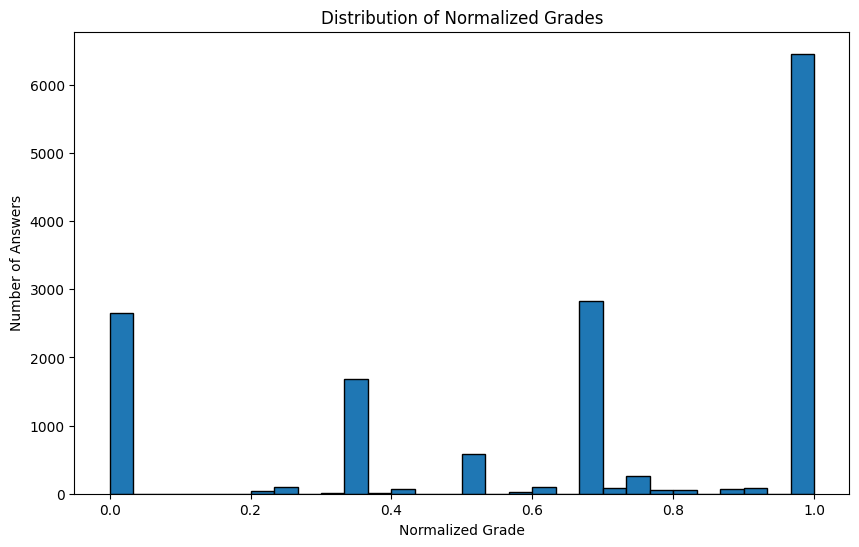

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df["normalized_grade"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Normalized Grade")
plt.ylabel("Number of Answers")
plt.title("Distribution of Normalized Grades")

plt.show()

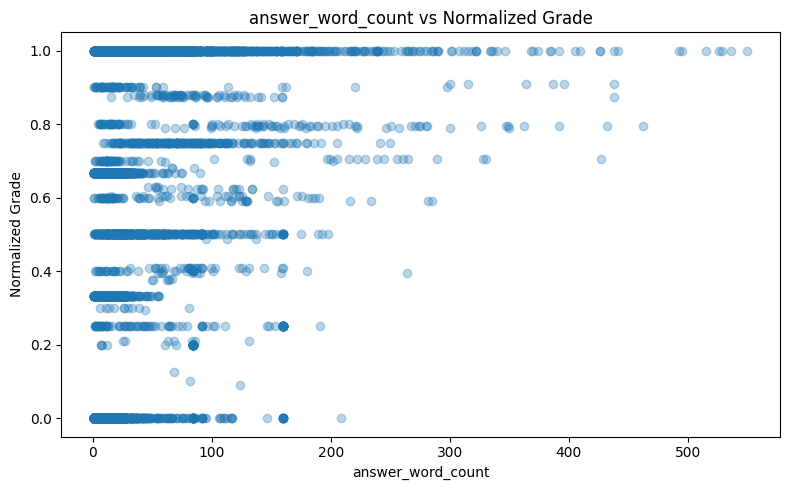

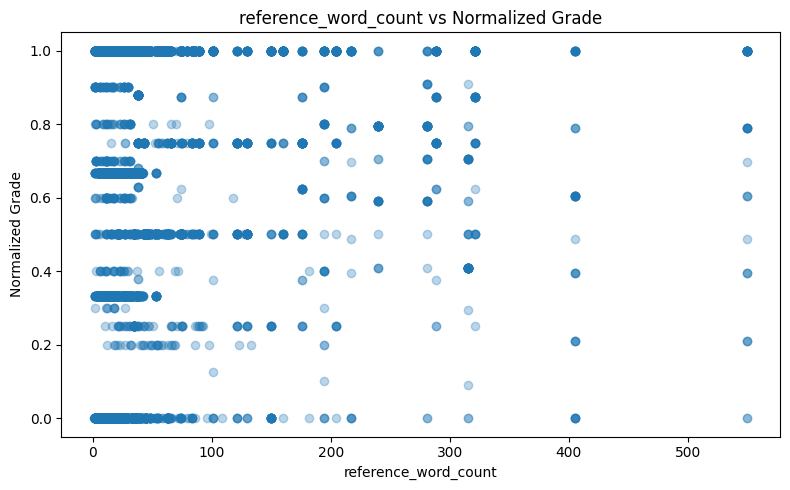

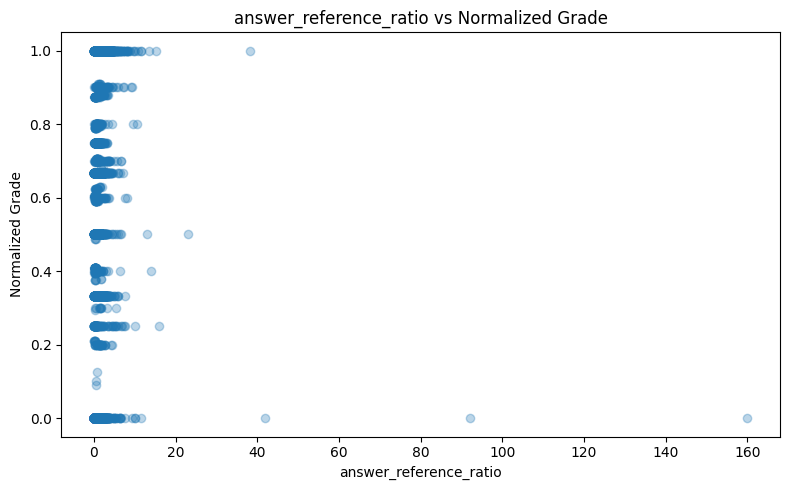

In [ ]:
import matplotlib.pyplot as plt

features = [
    "answer_word_count",
    "reference_word_count",
    "answer_reference_ratio"
]

for feature in features:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df[feature],
        df["normalized_grade"],
        alpha=0.3
    )

    plt.xlabel(feature)
    plt.ylabel("Normalized Grade")
    plt.title(f"{feature} vs Normalized Grade")

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Handle missing values
df["question"] = df["question"].fillna("")

# Feature engineering
df["length_difference"] = (
    df["answer_word_count"] - df["reference_word_count"]
)

df["length_ratio"] = (
    df["answer_word_count"] /
    df["reference_word_count"].replace(0, 1)
)

# Features
features = [
    "weight",
    "answer_word_count",
    "reference_word_count",
    "answer_reference_ratio",
    "length_difference",
    "length_ratio"
]

X = df[features]
y = df["normalized_grade"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (12122, 6)
X_test : (3031, 6)
y_train: (12122,)
y_test : (3031,)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_reg = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regressor Results")
print("--------------------------------")
print(f"MAE  : {mae_rf:.4f}")
print(f"MSE  : {mse_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Regressor Results
--------------------------------
MAE  : 0.0016
MSE  : 0.0002
RMSE : 0.0124
R²   : 0.9989


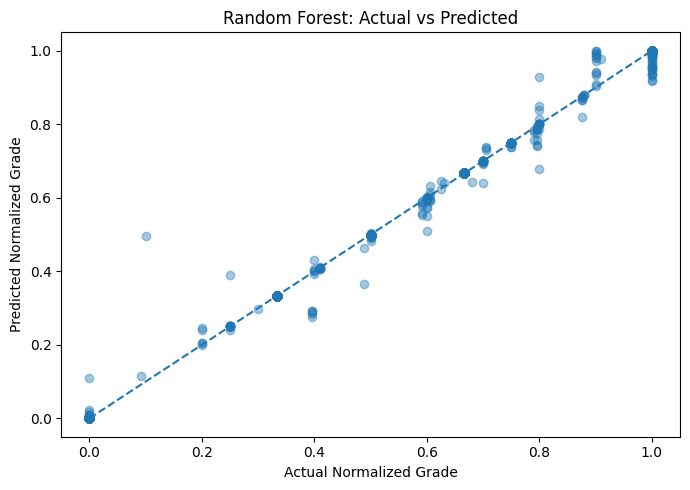

In [ ]:
import matplotlib.pyplot as plt

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.4)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Actual Normalized Grade")
plt.ylabel("Predicted Normalized Grade")
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

features = [
    "weight",
    "answer_word_count",
    "reference_word_count",
    "answer_reference_ratio",
    "length_difference",
    "length_ratio"
]

X = df[features]
y = df["normalized_grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SVR model
svr = SVR(
    kernel="rbf",
    C=10,
    gamma="scale",
    epsilon=0.01
)

svr.fit(X_train_scaled, y_train)

# Predictions
y_pred_svr = svr.predict(X_test_scaled)

# Evaluation
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("SVR Results")
print("-----------")
print(f"MAE  : {mae_svr:.4f}")
print(f"MSE  : {mse_svr:.4f}")
print(f"RMSE : {rmse_svr:.4f}")
print(f"R²   : {r2_svr:.4f}")

SVR Results
-----------
MAE  : 0.2345
MSE  : 0.1216
RMSE : 0.3486
R²   : 0.1273


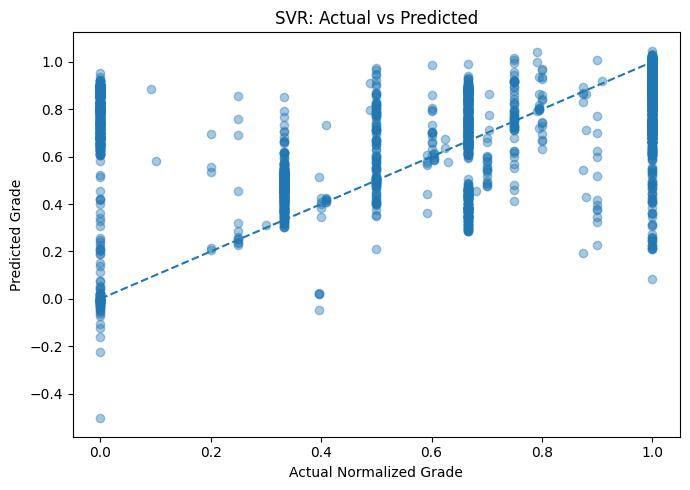

In [ ]:
import matplotlib.pyplot as plt

# Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_svr, alpha=0.4)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Actual Normalized Grade")
plt.ylabel("Predicted Grade")
plt.title("SVR: Actual vs Predicted")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

def classify_grade(score):
    if score < 0.4:
        return "Poor"
    elif score < 0.6:
        return "Average"
    elif score < 0.8:
        return "Good"
    else:
        return "Excellent"

df["grade_class"] = df["normalized_grade"].apply(classify_grade)

print("Class Distribution:")
print(df["grade_class"].value_counts())

print("\nClass Percentage:")
print((df["grade_class"].value_counts(normalize=True) * 100).round(2))


Class Distribution:
grade_class
Excellent    6660
Poor         4499
Good         3324
Average       670
Name: count, dtype: int64

Class Percentage:
grade_class
Excellent    43.95
Poor         29.69
Good         21.94
Average       4.42
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

features = [
    "weight",
    "answer_word_count",
    "reference_word_count",
    "answer_reference_ratio",
    "length_difference",
    "length_ratio"
]

X = df[features]
y = df["grade_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svc = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svc.fit(X_train_scaled, y_train)

y_pred_svc = svc.predict(X_test_scaled)

print("SVC Results")
print("-----------")
print(f"Accuracy : {accuracy_score(y_test, y_pred_svc):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svc))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svc))

SVC Results
-----------
Accuracy : 0.5506

Classification Report:
              precision    recall  f1-score   support

     Average       0.72      0.45      0.55       134
   Excellent       0.56      0.81      0.66      1332
        Good       0.71      0.09      0.16       665
        Poor       0.51      0.52      0.51       900

    accuracy                           0.55      3031
   macro avg       0.62      0.47      0.47      3031
weighted avg       0.58      0.55      0.50      3031

Confusion Matrix:
[[  60   36    4   34]
 [  16 1081   10  225]
 [   1  405   59  200]
 [   6  415   10  469]]


<Figure size 700x600 with 0 Axes>

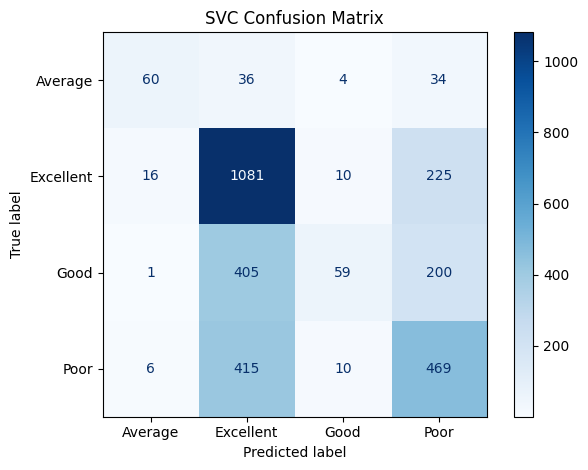

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svc,
    cmap="Blues",
    values_format="d"
)

plt.title("SVC Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results
---------------------------
Accuracy : 0.4754

Classification Report:
              precision    recall  f1-score   support

     Average       0.50      0.07      0.12       134
   Excellent       0.48      0.97      0.64      1332
        Good       0.12      0.01      0.01       665
        Poor       0.52      0.14      0.23       900

    accuracy                           0.48      3031
   macro avg       0.40      0.30      0.25      3031
weighted avg       0.41      0.48      0.36      3031

Confusion Matrix:
[[   9   73   22   30]
 [   1 1297    6   28]
 [   3  593    5   64]
 [   5  755   10  130]]


<Figure size 700x600 with 0 Axes>

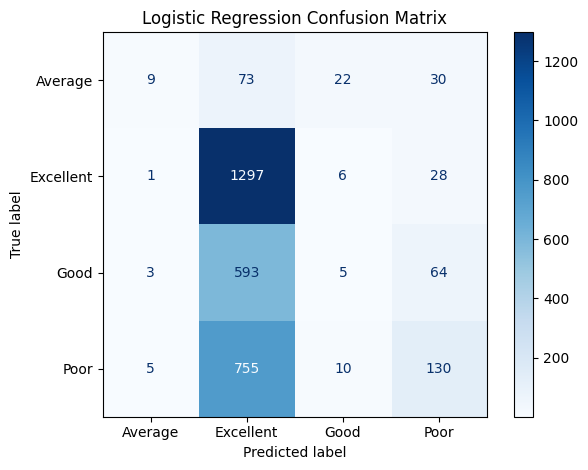

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Random Forest Regressor",
        "SVR",
        "SVC",
        "Logistic Regression"
    ],
    "Task": [
        "Regression",
        "Regression",
        "Classification",
        "Classification"
    ],
    "MAE": [
        0.0016,
        0.2345,
        None,
        None
    ],
    "RMSE": [
        0.0124,
        0.3486,
        None,
        None
    ],
    "R2": [
        0.9989,
        0.1273,
        None,
        None
    ],
    "Accuracy": [
        None,
        None,
        0.5506,
        0.4754
    ],
    "Macro_F1": [
        None,
        None,
        0.47,
        0.25
    ]
})

display(results)

,Model,Task,MAE,RMSE,R2,Accuracy,Macro_F1
0,Random Forest Regressor,Regression,0.0016,0.0124,0.9989,NaN,NaN
1,SVR,Regression,0.2345,0.3486,0.1273,NaN,NaN
2,SVC,Classification,NaN,NaN,NaN,0.5506,0.47
3,Logistic Regression,Classification,NaN,NaN,NaN,0.4754,0.25


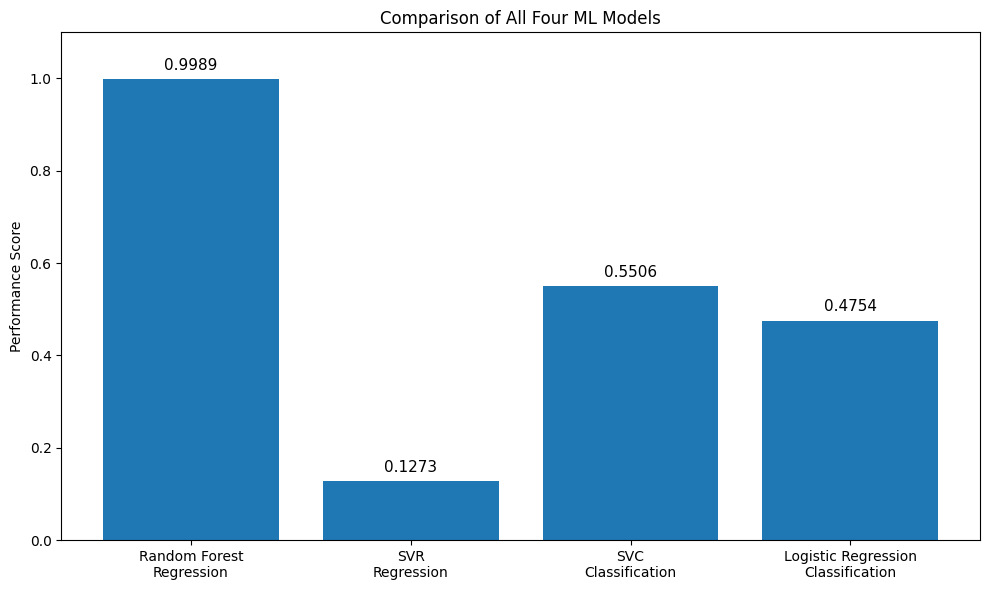

In [ ]:
import matplotlib.pyplot as plt

models = [
    "Random Forest\nRegression",
    "SVR\nRegression",
    "SVC\nClassification",
    "Logistic Regression\nClassification"
]

scores = [
    0.9989,   # R²
    0.1273,   # R²
    0.5506,   # Accuracy
    0.4754    # Accuracy
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, scores)

plt.ylabel("Performance Score")
plt.title("Comparison of All Four ML Models")
plt.ylim(0, 1.1)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{score:.4f}",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()